# R2d — Estadística de R2c (base vs LoRA, ROI oráculo)

**Objetivo:** saber si la mejora de R2c es real o puede ser ruido de 60 ventanas.

| Pregunta | Prueba | Por qué esa |
|---|---|---|
| ¿Bajaron las falsas alarmas (26/30 → 12/30)? | **McNemar exacto** | Las mismas 30 negativas pasan por los dos modelos → datos **pareados**. Fisher asume grupos independientes. |
| ¿Subió el AUC (0.648 → 0.753)? | **DeLong pareado** + **bootstrap pareado estratificado** | DeLong es la prueba clásica para dos AUC sobre los mismos casos; el bootstrap la confirma sin supuestos. |
| ¿Cómo se ve? | Curva ROC + histograma de P(sí) | Para el reporte. |

*Analogía:* McNemar es como comparar a dos jueces que califican **los mismos** exámenes: solo importan los exámenes donde **no** están de acuerdo. Si en 14 desacuerdos el LoRA siempre acierta y el base siempre falla, no es suerte.

No usa GPU. Solo necesita `test_roi_base_ebfa594f.csv` y `test_roi_lora_ebfa594f.csv`.

In [ ]:
# ===== 1. Configuración =====
HUELLA = "ebfa594f"
ARCH_BASE = f"test_roi_base_{HUELLA}.csv"
ARCH_LORA = f"test_roi_lora_{HUELLA}.csv"

# Si la detección automática de columnas falla, escribe aquí el nombre real (si no, deja None)
COL_ID    = None   # identificador de ventana (para emparejar base y LoRA)
COL_REAL  = None   # etiqueta real: ¿hay choque? (true/false, 1/0)
COL_PROB  = None   # P(incidente=true) de los logits
COL_PRED  = None   # respuesta generada en el JSON: incidente true/false

N_BOOT = 10_000
SEMILLA = 2026

In [ ]:
# ===== 2. Montar Drive y encontrar los CSV =====
import os, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = '/content/drive/MyDrive'
except ImportError:
    RAIZ = '.'   # para correr fuera de Colab

def buscar(nombre):
    hits = glob.glob(f'{RAIZ}/**/{nombre}', recursive=True)
    if not hits:
        raise FileNotFoundError(f'No encontré {nombre} dentro de {RAIZ}')
    if len(hits) > 1:
        print(f'⚠ Varias copias de {nombre}, uso la primera:', *hits, sep='\n   ')
    return hits[0]

# Primero en la ruta esperada (rápido); si no, búsqueda recursiva
esperada = f'{RAIZ}/roadvision/resultados_qwen'
ruta_base = f'{esperada}/{ARCH_BASE}' if os.path.exists(f'{esperada}/{ARCH_BASE}') else buscar(ARCH_BASE)
ruta_lora = f'{esperada}/{ARCH_LORA}' if os.path.exists(f'{esperada}/{ARCH_LORA}') else buscar(ARCH_LORA)
CARPETA = os.path.dirname(ruta_lora)
SALIDA = f'{CARPETA}/r2d_{HUELLA}'
os.makedirs(SALIDA, exist_ok=True)
print('base :', ruta_base); print('lora :', ruta_lora); print('salida:', SALIDA)

Mounted at /content/drive
base : /content/drive/MyDrive/roadvision/resultados_qwen/test_roi_base_ebfa594f.csv
lora : /content/drive/MyDrive/roadvision/resultados_qwen/test_roi_lora_ebfa594f.csv
salida: /content/drive/MyDrive/roadvision/resultados_qwen/r2d_ebfa594f


In [ ]:
# ===== 3. Cargar y detectar columnas =====
import pandas as pd, numpy as np

base = pd.read_csv(ruta_base)
lora = pd.read_csv(ruta_lora)
print('Columnas base:', list(base.columns))
print('Columnas lora:', list(lora.columns))
display(base.head(3))

def a_bool(s):
    if s.dtype == bool: return s.astype(int)
    m = {'true':1,'false':0,'1':1,'0':0,'si':1,'sí':1,'no':0,'yes':1,'positivo':1,'negativo':0,'positiva':1,'negativa':0,'1.0':1,'0.0':0}
    return s.astype(str).str.strip().str.lower().map(m)   # NaN = no interpretable

def detectar(df, fijo, exactos, contiene, excluir=()):
    if fijo:
        assert fijo in df.columns, f'{fijo} no está en el CSV'
        return fijo
    cols = {c.lower(): c for c in df.columns}
    for e in exactos:
        if e in cols: return cols[e]
    for c_low, c in cols.items():
        if any(s in c_low for s in contiene) and not any(x in c_low for x in excluir):
            return c
    return None

def es_binaria(s):
    v = a_bool(s)
    return v.notna().all() and set(v.unique()) <= {0, 1} and v.nunique() == 2

def detectar_real(df):
    if COL_REAL:
        return COL_REAL
    # Solo columnas que de verdad son true/false (evita tipo_real, segundo_real, etc.)
    pref = ['etiqueta','y_true','y','real','gt','label','positivo','es_positivo','es_choque',
            'incidente_real','incidente_gt','gt_incidente','verdad','choque','hay_choque','clase']
    malas = ['p_','prob','pred','modelo','salida','respuesta','json']
    cols = {c.lower(): c for c in df.columns}
    for e in pref:
        if e in cols and es_binaria(df[cols[e]]): return cols[e]
    for cl_, c in cols.items():
        if any(s in cl_ for s in ['etiq','real','gt','verdad','label','positiv','choque','clase']) \
           and not any(m in cl_ for m in malas) and es_binaria(df[c]):
            return c
    return None

def columnas(df):
    real = detectar_real(df)
    prob = detectar(df, COL_PROB,
        ['p_si','p_incidente','p_true','prob','prob_si','p_yes','score','p'],
        ['p_si','prob','p_true','p_inc','score'])
    pred = detectar(df, COL_PRED,
        ['incidente_pred','pred','prediccion','pred_incidente','incidente','respuesta_incidente'],
        ['pred','incidente'], excluir=['real','p_','prob','gt'])
    vid = detectar(df, COL_ID,
        ['ventana_id','id','clip_id','id_ventana','clip','ventana'],
        ['ventana','clip_id','_id'])
    return dict(id=vid, real=real, prob=prob, pred=pred)

cb, cl = columnas(base), columnas(lora)
print('\nDetectado base:', cb); print('Detectado lora:', cl)
for k in ['real','prob']:
    assert cb[k] and cl[k], f'No encontré la columna "{k}". Ponla a mano en la celda 1 (COL_{k.upper()}).'

Columnas base: ['clase', 'inicio', 'fin', 't_rel', 'video', 'ruta_rel', 't_choque', 'tipo_real', 'dominio', 'roi', 'ruta', 'fps_ef', 'dur', 'respuesta', 'pred_incidente', 'pred_tipo', 'pred_segundo_aprox', 'camara_fija', 'descripcion', 'campos_malos', 'formato', 'segundos', 'respuesta_cruda', 'p_si']
Columnas lora: ['clase', 'inicio', 'fin', 't_rel', 'video', 'ruta_rel', 't_choque', 'tipo_real', 'dominio', 'roi', 'ruta', 'fps_ef', 'dur', 'respuesta', 'pred_incidente', 'pred_tipo', 'pred_segundo_aprox', 'camara_fija', 'descripcion', 'campos_malos', 'formato', 'segundos', 'respuesta_cruda', 'p_si']


,clase,inicio,fin,t_rel,video,ruta_rel,t_choque,tipo_real,dominio,roi,...,pred_incidente,pred_tipo,pred_segundo_aprox,camara_fija,descripcion,campos_malos,formato,segundos,respuesta_cruda,p_si
0,positiva,6.411179,14.411179,2.171821,QbTAfMWdSN0_00,real_videos/QbTAfMWdSN0_00.mp4,8.583,t-bone,real,"(0.3947563621118055, 0.5248460035678482, 0.121...",...,True,en_t,4.0,NaN,NaN,descripcion,ok,6.10,"```json\n{\n ""incidente"": true,\n ""tipo"": ""e...",0.746139
1,negativa,0.000000,5.583000,NaN,QbTAfMWdSN0_00,real_videos/QbTAfMWdSN0_00.mp4,8.583,t-bone,real,"(0.3947563621118055, 0.5248460035678482, 0.121...",...,True,en_t,3.0,NaN,NaN,descripcion,ok,4.48,"```json\n{\n ""incidente"": true,\n ""tipo"": ""e...",0.833325
2,positiva,5.014127,13.014127,5.318873,sKJdbm04q6U_00,real_videos/sKJdbm04q6U_00.mp4,10.333,single,real,"(0.1475874681825989, 0.4544486038773149, 0.024...",...,True,en_t,3.0,NaN,NaN,descripcion,ok,6.45,"```json\n{\n ""incidente"": true,\n ""tipo"": ""e...",0.731059



Detectado base: {'id': None, 'real': 'clase', 'prob': 'p_si', 'pred': 'pred_incidente'}
Detectado lora: {'id': None, 'real': 'clase', 'prob': 'p_si', 'pred': 'pred_incidente'}


In [ ]:
# ===== 4. Normalizar y emparejar =====
# Columnas que salen del modelo (no sirven como llave porque cambian entre base y LoRA)
DEL_MODELO = ['p_','prob','pred','score','logit','lat','tiempo','seg_','segundos','respuesta','salida',
              'json','raw','texto','valido','error','nan','reintento','tipo_pred','modelo']

def llave(df, c):
    if c['id']:
        return [c['id']]
    pistas = ['video','clip','archivo','ruta','path','nombre','inicio','start','t0','t_ini','ventana',
              'fin','end','t1','frame','escena','camara']
    k = [col for col in df.columns
         if any(p in col.lower() for p in pistas) and not any(m in col.lower() for m in DEL_MODELO)
         and df[col].notna().any()]
    # Basta con la combinación más corta que ya sea única (p. ej. video + inicio)
    for n in range(1, len(k) + 1):
        if not df[k[:n]].duplicated().any():
            return k[:n]
    return k

def limpiar(df, c, nombre, k):
    t = pd.DataFrame({
        'y': a_bool(df[c['real']]),
        f'p_{nombre}': pd.to_numeric(df[c['prob']], errors='coerce'),
    })
    if c['pred']: t[f'pred_{nombre}'] = a_bool(df[c['pred']])
    if k: t['id'] = df[k].astype(object).where(df[k].notna(), '').astype(str).agg('|'.join, axis=1)
    return t

kb = llave(base, cb)
k = [x for x in kb if x in lora.columns]
print('Llave para emparejar:', k or '(ninguna: se usará el orden de filas)')
tb, tl = limpiar(base, cb, 'base', k), limpiar(lora, cl, 'lora', k)
print('Etiqueta real base:', tb['y'].value_counts(dropna=False).to_dict(),
      '| lora:', tl['y'].value_counts(dropna=False).to_dict())

if k and tb['id'].is_unique and tl['id'].is_unique:
    d = tb.merge(tl, on='id', suffixes=('', '_l'))
    if len(d) != len(tb) or len(d) != len(tl):
        print('Ids solo en base:', sorted(set(tb.id) - set(tl.id))[:5])
        print('Ids solo en lora:', sorted(set(tl.id) - set(tb.id))[:5])
        raise AssertionError(f'Solo coinciden {len(d)} de {len(tb)}/{len(tl)} ventanas')
    malas = d[d['y'] != d['y_l']]
    if len(malas):
        display(malas.head(10))
        raise AssertionError(f'{len(malas)} ventanas con etiqueta distinta entre base y LoRA. '
                             f'Revisa que COL_REAL ({cb["real"]}) sea la etiqueta verdadera.')
    d = d.drop(columns='y_l')
    print(f'Emparejado por {k} ✔')
else:
    if k: print('⚠ La llave tiene repetidos; intento por orden de filas')
    assert len(tb) == len(tl), 'Distinto número de filas y sin llave para emparejar'
    malas = np.where(tb['y'].values != tl['y'].values)[0]
    if len(malas):
        print(f'{len(malas)} filas no coinciden. Primeras:')
        display(pd.concat([base.iloc[malas[:5]].add_suffix('_base').reset_index(drop=True),
                           lora.iloc[malas[:5]].add_suffix('_lora').reset_index(drop=True)], axis=1))
        raise AssertionError('Sin llave y las etiquetas no coinciden fila a fila. Pon COL_ID (o COL_REAL) en la celda 1.')
    d = pd.concat([tb, tl.drop(columns='y')], axis=1)
    print('⚠ Emparejado por orden de filas (las etiquetas coinciden fila a fila)')

assert d['y'].notna().all(), 'Hay etiquetas reales no interpretables'
for m in ['base','lora']:
    n_nan = d[f'p_{m}'].isna().sum()
    if n_nan: print(f'⚠ {m}: {n_nan} probabilidades NaN → se excluyen del AUC')
d['y'] = d['y'].astype(int)
print(f'Ventanas: {len(d)}  (positivas {d.y.sum()}, negativas {(1-d.y).sum()})')
display(d.head())

Llave para emparejar: ['inicio', 'fin']
Etiqueta real base: {1: 30, 0: 30} | lora: {1: 30, 0: 30}
Emparejado por ['inicio', 'fin'] ✔
Ventanas: 60  (positivas 30, negativas 30)


,y,p_base,pred_base,id,p_lora,pred_lora
0,1,0.746139,1,6.411178779437995|14.411178779437996,0.734120,1
1,0,0.833325,1,0.0|5.583,0.817574,1
2,1,0.731059,1,5.01412690511693|13.01412690511693,0.592667,1
3,0,0.740174,1,0.0|7.333,0.622459,1
4,1,0.785309,1,6.939490564540295|14.939490564540296,0.882428,1


## 5. Falsas alarmas y detecciones — McNemar exacto

Tabla de desacuerdos sobre las **negativas**:

|  | LoRA sin alarma | LoRA con alarma |
|---|---|---|
| **Base sin alarma** | a | b |
| **Base con alarma** | c | d |

Solo cuentan **b** y **c**. Si los modelos fueran igual de buenos, cada desacuerdo sería un volado 50/50 → prueba binomial exacta con n = b + c.

In [ ]:
# ===== 5. McNemar =====
from scipy.stats import binomtest

def mcnemar(x_base, x_lora, que):
    x_base, x_lora = np.asarray(x_base, int), np.asarray(x_lora, int)
    b = int(((x_base == 0) & (x_lora == 1)).sum())   # solo LoRA lo marca
    c = int(((x_base == 1) & (x_lora == 0)).sum())   # solo base lo marca
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
    print(f'{que}: base {x_base.sum()}/{len(x_base)}  →  LoRA {x_lora.sum()}/{len(x_lora)}')
    print(f'   desacuerdos: solo base={c}, solo LoRA={b}  →  McNemar exacto p = {p:.4g}')
    return dict(prueba=que, base=f'{x_base.sum()}/{len(x_base)}', lora=f'{x_lora.sum()}/{len(x_lora)}',
                solo_base=c, solo_lora=b, p_mcnemar=p)

filas_mc = []
if 'pred_base' in d and 'pred_lora' in d:
    ok = d['pred_base'].notna() & d['pred_lora'].notna()
    if (~ok).any(): print(f'⚠ {(~ok).sum()} ventanas con respuesta no interpretable → se excluyen de McNemar')
    neg, pos = d[ok & (d.y == 0)], d[ok & (d.y == 1)]
    filas_mc.append(mcnemar(neg.pred_base, neg.pred_lora, 'Falsas alarmas (negativas)'))
    filas_mc.append(mcnemar(pos.pred_base, pos.pred_lora, 'Choques detectados (positivas)'))
else:
    print('⚠ No hay columna de respuesta generada; McNemar se omite. Ponla en COL_PRED si existe.')

Falsas alarmas (negativas): base 26/30  →  LoRA 12/30
   desacuerdos: solo base=14, solo LoRA=0  →  McNemar exacto p = 0.0001221
Choques detectados (positivas): base 28/30  →  LoRA 26/30
   desacuerdos: solo base=2, solo LoRA=0  →  McNemar exacto p = 0.5


## 6. AUC — DeLong pareado

DeLong calcula la varianza del AUC sin remuestrear, usando **componentes** por caso: para cada positiva, qué fracción de negativas queda por debajo; y al revés. Como base y LoRA ven los **mismos** casos, también calcula la covarianza entre los dos AUC → la prueba de la diferencia es mucho más fina que comparar dos intervalos sueltos.

In [ ]:
# ===== 6. DeLong =====
from scipy.stats import norm
from sklearn.metrics import roc_auc_score

dd = d.dropna(subset=['p_base','p_lora']).reset_index(drop=True)
y = dd['y'].values
S = np.vstack([dd['p_base'].values, dd['p_lora'].values])   # 2 × n

def delong(y, S):
    pos, neg = S[:, y == 1], S[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    # psi(x, z) = 1 si x > z, 0.5 si empate
    psi = (pos[:, :, None] > neg[:, None, :]) + 0.5 * (pos[:, :, None] == neg[:, None, :])
    V10 = psi.mean(axis=2)        # k × m   (por positiva)
    V01 = psi.mean(axis=1)        # k × n   (por negativa)
    auc = V10.mean(axis=1)
    cov = np.cov(V10) / m + np.cov(V01) / n
    return auc, cov

auc, cov = delong(y, S)
se = np.sqrt(np.diag(cov))
dif = auc[1] - auc[0]
se_dif = np.sqrt(cov[0,0] + cov[1,1] - 2*cov[0,1])
z = dif / se_dif
p_delong = 2 * norm.sf(abs(z))

assert np.allclose(auc, [roc_auc_score(y, S[0]), roc_auc_score(y, S[1])]), 'DeLong no coincide con sklearn'
ic = lambda a, s: (a - 1.96*s, a + 1.96*s)
for nom, a, s in zip(['base','LoRA'], auc, se):
    lo, hi = ic(a, s); print(f'AUC {nom:4s} = {a:.3f}  (SE {s:.3f}, IC95 {lo:.3f}–{hi:.3f})')
lo, hi = ic(dif, se_dif)
print(f'Diferencia = {dif:+.3f}  (IC95 {lo:+.3f} a {hi:+.3f})   z = {z:.2f}   p DeLong = {p_delong:.4g}')
print(f'Correlación entre AUCs: {cov[0,1]/(se[0]*se[1]):.2f}')

AUC base = 0.648  (SE 0.072, IC95 0.507–0.790)
AUC LoRA = 0.753  (SE 0.064, IC95 0.628–0.879)
Diferencia = +0.105  (IC95 +0.007 a +0.203)   z = 2.09   p DeLong = 0.03666
Correlación entre AUCs: 0.73


## 7. AUC — bootstrap pareado estratificado

Se sortean ventanas **con reemplazo**, manteniendo 30 positivas y 30 negativas en cada sorteo (estratificado), y **la misma muestra** se evalúa con base y LoRA (pareado). Con 10,000 sorteos sale un intervalo percentil de la diferencia.

In [ ]:
# ===== 7. Bootstrap =====
rng = np.random.default_rng(SEMILLA)
ip, ineg = np.where(y == 1)[0], np.where(y == 0)[0]
boot = np.empty((N_BOOT, 2))
for i in range(N_BOOT):
    idx = np.concatenate([rng.choice(ip, len(ip)), rng.choice(ineg, len(ineg))])
    boot[i] = roc_auc_score(y[idx], S[0, idx]), roc_auc_score(y[idx], S[1, idx])
bd = boot[:, 1] - boot[:, 0]
pct = lambda v: np.percentile(v, [2.5, 97.5])
p_boot = min(1.0, 2 * min((bd <= 0).mean(), (bd >= 0).mean()))
for j, nom in enumerate(['base','LoRA']):
    lo, hi = pct(boot[:, j]); print(f'AUC {nom:4s}: IC95 bootstrap {lo:.3f}–{hi:.3f}')
lo_b, hi_b = pct(bd)
print(f'Diferencia: IC95 bootstrap {lo_b:+.3f} a {hi_b:+.3f}   P(LoRA ≤ base) = {(bd <= 0).mean():.3f}   p ≈ {p_boot:.4g}')

AUC base: IC95 bootstrap 0.503–0.783
AUC LoRA: IC95 bootstrap 0.622–0.870
Diferencia: IC95 bootstrap +0.007 a +0.207   P(LoRA ≤ base) = 0.018   p ≈ 0.035


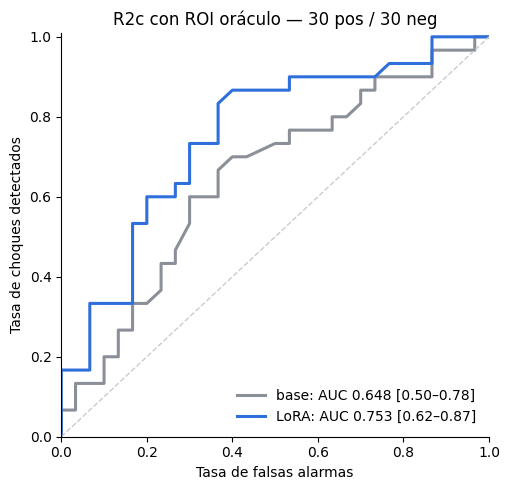

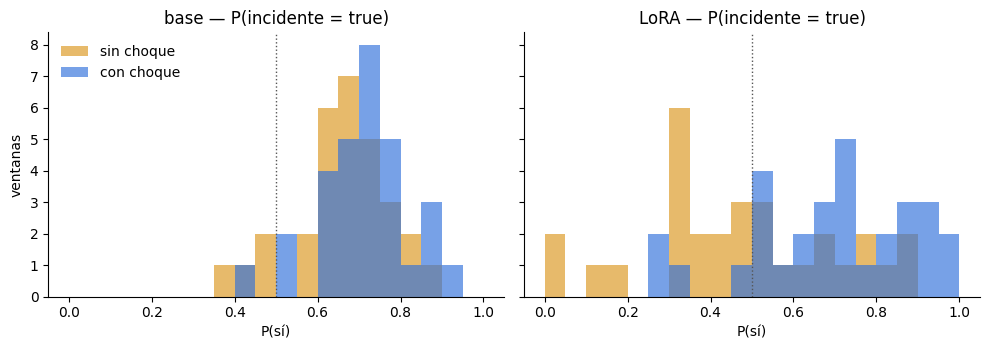

In [ ]:
# ===== 8. Figuras para el reporte =====
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

COL = {'base': '#8a8f98', 'LoRA': '#2f6fdb'}
fig, ax = plt.subplots(figsize=(5.2, 5))
for j, nom in enumerate(['base','LoRA']):
    fpr, tpr, _ = roc_curve(y, S[j])
    lo, hi = pct(boot[:, j])
    ax.plot(fpr, tpr, color=COL[nom], lw=2.2, label=f'{nom}: AUC {auc[j]:.3f} [{lo:.2f}–{hi:.2f}]')
ax.plot([0,1], [0,1], ls='--', color='#c8ccd2', lw=1)
ax.set(xlabel='Tasa de falsas alarmas', ylabel='Tasa de choques detectados',
       title=f'R2c con ROI oráculo — {len(ip)} pos / {len(ineg)} neg', xlim=(0,1), ylim=(0,1.01))
ax.legend(loc='lower right', frameon=False); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(f'{SALIDA}/roc_r2c.png', dpi=200); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, j, nom in zip(axs, [0, 1], ['base','LoRA']):
    ax.hist(S[j, y == 0], bins=bins, alpha=.75, color='#e0a33a', label='sin choque')
    ax.hist(S[j, y == 1], bins=bins, alpha=.65, color='#2f6fdb', label='con choque')
    ax.axvline(.5, ls=':', color='#555', lw=1)
    ax.set(title=f'{nom} — P(incidente = true)', xlabel='P(sí)'); ax.spines[['top','right']].set_visible(False)
axs[0].set_ylabel('ventanas'); axs[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(f'{SALIDA}/hist_psi_r2c.png', dpi=200); plt.show()

In [ ]:
# ===== 9. Resumen para el reporte =====
alfa = 0.05
res = pd.DataFrame(filas_mc)
lo_d, hi_d = ic(dif, se_dif)
auc_tab = pd.DataFrame([
    dict(métrica='AUC base', valor=round(auc[0],3), ic95_delong=f'{ic(auc[0],se[0])[0]:.3f}–{ic(auc[0],se[0])[1]:.3f}',
         ic95_boot=f'{pct(boot[:,0])[0]:.3f}–{pct(boot[:,0])[1]:.3f}'),
    dict(métrica='AUC LoRA', valor=round(auc[1],3), ic95_delong=f'{ic(auc[1],se[1])[0]:.3f}–{ic(auc[1],se[1])[1]:.3f}',
         ic95_boot=f'{pct(boot[:,1])[0]:.3f}–{pct(boot[:,1])[1]:.3f}'),
    dict(métrica='Diferencia', valor=round(dif,3), ic95_delong=f'{lo_d:+.3f} a {hi_d:+.3f}',
         ic95_boot=f'{lo_b:+.3f} a {hi_b:+.3f}', p_delong=p_delong, p_boot=p_boot),
])
display(res); display(auc_tab)
res.to_csv(f'{SALIDA}/mcnemar_r2c.csv', index=False)
auc_tab.to_csv(f'{SALIDA}/auc_r2c.csv', index=False)

print('\n=== Frases para el reporte ===')
for r in filas_mc:
    sig = 'significativa' if r['p_mcnemar'] < alfa else 'no significativa'
    print(f"• {r['prueba']}: {r['base']} → {r['lora']} (McNemar exacto, p = {r['p_mcnemar']:.3g}; diferencia {sig}).")
sig_auc = 'significativa' if (p_delong < alfa and lo_b > 0) else 'no significativa con este tamaño de test'
print(f'• AUC: {auc[0]:.3f} → {auc[1]:.3f}, diferencia {dif:+.3f} '
      f'(IC95 DeLong {lo_d:+.3f} a {hi_d:+.3f}, p = {p_delong:.3g}; bootstrap {lo_b:+.3f} a {hi_b:+.3f}); {sig_auc}.')
print('• Supuesto: la ROI viene de la anotación (oráculo) → techo optimista del supervisor.')
print('\nArchivos en', SALIDA, ':', sorted(os.listdir(SALIDA)))

,prueba,base,lora,solo_base,solo_lora,p_mcnemar
0,Falsas alarmas (negativas),26/30,12/30,14,0,0.000122
1,Choques detectados (positivas),28/30,26/30,2,0,0.500000


,métrica,valor,ic95_delong,ic95_boot,p_delong,p_boot
0,AUC base,0.648,0.507–0.790,0.503–0.783,NaN,NaN
1,AUC LoRA,0.753,0.628–0.879,0.622–0.870,NaN,NaN
2,Diferencia,0.105,+0.007 a +0.203,+0.007 a +0.207,0.036659,0.035



=== Frases para el reporte ===
• Falsas alarmas (negativas): 26/30 → 12/30 (McNemar exacto, p = 0.000122; diferencia significativa).
• Choques detectados (positivas): 28/30 → 26/30 (McNemar exacto, p = 0.5; diferencia no significativa).
• AUC: 0.648 → 0.753, diferencia +0.105 (IC95 DeLong +0.007 a +0.203, p = 0.0367; bootstrap +0.007 a +0.207); significativa.
• Supuesto: la ROI viene de la anotación (oráculo) → techo optimista del supervisor.

Archivos en /content/drive/MyDrive/roadvision/resultados_qwen/r2d_ebfa594f : ['auc_r2c.csv', 'hist_psi_r2c.png', 'mcnemar_r2c.csv', 'roc_r2c.png']
